# 4. Run experiments you can trust

**Goal:** compare model sizes fairly, choose using validation, and inspect the test split only after the choice. This notebook runs independently and trains four small models.

### Definitions

| Term | Definition |
|---|---|
| Training split | Examples used for gradient updates |
| Validation split | Examples used for selecting settings and models |
| Test split | Examples reserved for final evaluation after model choices |
| Leakage | Evaluation information improperly influences training or decisions |
| Baseline | A simple reference you must compare against |
| Hyperparameter | Setting chosen outside gradient updates, such as width or learning rate |
| Random seed | Sets pseudorandom state; useful for repeatability, not a quality guarantee |
| Controlled experiment | Change a specific factor while holding the comparison budget and procedure fixed |
| Overfitting | Improving fit to training data without matching held-out improvement |
| Perplexity | `exp(mean next-token cross-entropy)`; compare only under compatible tokenization/data |
| Ablation | Remove or change a component to measure its contribution |

**Boundary:** this authored corpus has only 80 simple sentences sharing grammar. Held-out combinations are useful for this lesson, but they do not establish general language ability.

In [1]:
from pathlib import Path
import sys

# Find the lesson folder from the notebook folder, mini_llm, or repository root.
candidates = [Path.cwd(), Path.cwd() / "learning_path",
              Path.cwd() / "mini_llm" / "learning_path"]
lesson_dir = next((p.resolve() for p in candidates if (p / "lab.py").is_file()), None)
if lesson_dir is None:
    raise FileNotFoundError("Open this notebook from learning_path, mini_llm, or the repository root.")
if str(lesson_dir) not in sys.path:
    sys.path.insert(0, str(lesson_dir))

import math
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import lab

torch.set_num_threads(2)
torch.manual_seed(42)
print("Local CPU lesson | PyTorch", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


Local CPU lesson | PyTorch 2.14.1


### Step A — split whole sentences before making token windows
If you create overlapping windows first and randomly split them, nearly identical text can appear on both sides. We split unique sentences first. This prevents cross-split windows, but related sentences still share words and structures by design.

There are 60 training, 10 validation and 10 test sentences. Do not inspect test scores while choosing settings.

In [2]:
splits = lab.sentence_splits()
assert all(len(set(lines)) == len(lines) for lines in splits.values())
assert set(splits["train"]).isdisjoint(splits["val"])
assert set(splits["train"]).isdisjoint(splits["test"])
assert set(splits["val"]).isdisjoint(splits["test"])
train_data, val_data = lab.text_ids(splits["train"]), lab.text_ids(splits["val"])
print({name: len(lines) for name, lines in splits.items()})
print("Uniform-character baseline loss:", round(math.log(len(lab.CHARS)), 3))

{'train': 60, 'val': 10, 'test': 10}
Uniform-character baseline loss: 4.575


### Step B — compare width while holding token budget fixed
Both widths use two heads, one block, context 24, batch size 8, 100 updates, the same text splits, and matched seeds. Each run sees `24 × 8 × 100 = 19,200` input tokens, although random windows can repeat tokens. This is **equal token budget**, not equal compute: wider models do more work per token.

We use two seeds to expose some variation; two runs are not enough for strong statistical conclusions. Validation batches are fixed by a separate seed and never update weights.

In [3]:
import time
rows = []
for width in (24, 48):
    for seed in (7, 19):
        torch.manual_seed(seed)
        config = lab.Config(context_length=24, embedding_dim=width, num_heads=2, num_layers=1)
        candidate = lab.SinoLM(config)
        start = time.perf_counter()
        losses = lab.train_lm(candidate, train_data, steps=100, seed=seed)
        rows.append(dict(width=width, seed=seed, model=candidate,
                         train=lab.evaluate(candidate, train_data),
                         val=lab.evaluate(candidate, val_data),
                         seconds=time.perf_counter()-start,
                         parameters=sum(p.numel() for p in candidate.parameters())))
for row in rows:
    print({k: round(v, 3) if isinstance(v, float) else v
           for k, v in row.items() if k != "model"})
mean_val = {width: sum(r["val"] for r in rows if r["width"] == width)/2 for width in (24, 48)}
chosen_width = min(mean_val, key=mean_val.get)
print("Mean validation losses:", mean_val)
print("Width chosen using validation only:", chosen_width)

{'width': 24, 'seed': 7, 'train': 1.98, 'val': 1.784, 'seconds': 0.454, 'parameters': 12601}
{'width': 24, 'seed': 19, 'train': 1.904, 'val': 1.815, 'seconds': 0.089, 'parameters': 12601}
{'width': 48, 'seed': 7, 'train': 1.554, 'val': 1.451, 'seconds': 0.107, 'parameters': 38929}
{'width': 48, 'seed': 19, 'train': 1.52, 'val': 1.446, 'seconds': 0.124, 'parameters': 38929}
Mean validation losses: {24: 1.7998506128787994, 48: 1.448183834552765}
Width chosen using validation only: 48


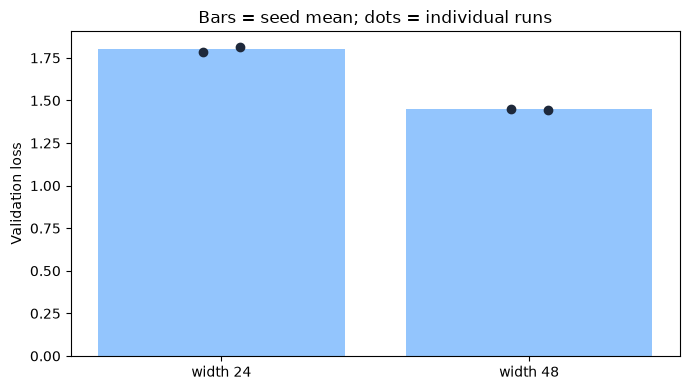

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for index, width in enumerate((24, 48)):
    values = [row["val"] for row in rows if row["width"] == width]
    ax.bar(index, mean_val[width], color="#93c5fd")
    ax.scatter([index-0.06, index+0.06], values, color="#1e293b", zorder=3)
ax.set_xticks([0, 1], ["width 24", "width 48"])
ax.set_ylabel("Validation loss"); ax.set_title("Bars = seed mean; dots = individual runs")
plt.tight_layout(); plt.show()

### Step C — use the test split after making the choice
We evaluate the selected architecture's two already-trained seed runs, without updating or reselecting them using test results. If you revise settings after seeing these scores, this split becomes part of development; a new independent test set is then needed.

In [5]:
test_data = lab.text_ids(splits["test"])
selected = [row for row in rows if row["width"] == chosen_width]
test_losses = [lab.evaluate(row["model"], test_data) for row in selected]
for row, loss in zip(selected, test_losses):
    print(f"Selected width {chosen_width}, seed {row['seed']}: test loss {loss:.3f}, perplexity {math.exp(loss):.2f}")
print("Mean test loss:", sum(test_losses)/len(test_losses))
assert all(math.isfinite(loss) for loss in test_losses)

Selected width 48, seed 7: test loss 1.521, perplexity 4.58
Selected width 48, seed 19: test loss 1.537, perplexity 4.65
Mean test loss: 1.5288128852844238


### Check your understanding

The wider model has lower training loss but higher validation loss. Which do you choose? Is the faster model always better?

<details><summary>Suggested answer — try first</summary>

Use the predefined selection criterion: lower mean validation loss in this experiment, while reporting runtime and parameter count. A real product may trade quality against latency or cost. Training loss alone does not justify selection.

</details>

### Your exercises
1. Add a third seed without changing any other setting. How stable is the result?
2. Compare dropout values using a new development experiment. Keep the token budget fixed.
3. Write down a hypothesis before running: “I expect X because Y.” Record whether results support it.
4. Explain why a low loss on repetitive practice text can coexist with poor open-ended responses.

**Completion criterion:** describe what changed, what stayed fixed, how you selected the winner, and what the result cannot prove.

Next: [05 — Instruction tuning and LoRA](05_instruction_tuning_and_lora.ipynb).